In [ ]:
# --- Repository setup ---
import os
from pathlib import Path

# Find the repository root (the folder that contains data/graphs) and work from there,
# so every relative path below resolves no matter where Jupyter was started.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'graphs').is_dir())
os.chdir(REPO_ROOT)
print('REPO_ROOT:', REPO_ROOT)


# Phase 2 Evaluation Comparison Analysis

This notebook compares the three Phase 2 evaluation systems using the CSV summaries in `results/`.

## Systems compared

1. **System 1: Neurosymbolic Clinical Graph Navigator**
   - Deterministic symbolic graph traversal.
   - Conversational interaction handled by a Virtual Patient LLM.
   - Expected to have highest path fidelity and strongest guideline adherence.

2. **System 2: LLM + Structured Graph JSON**
   - Navigator LLM receives structured graph JSON.
   - Expected to perform better than text-only navigation but still make some navigation errors.

3. **System 3: LLM + Raw Guideline Text**
   - Navigator LLM receives `mhgap_clinical_logic.md` and node catalog.
   - Expected to have lower path fidelity, higher hallucination/error rate, and higher token consumption.

## Metrics

Each run is compared against the deterministic ground-truth pathway.

- **Exact Path Match**: actual node sequence exactly matches the expected sequence.
- **Prefix Path Match**: model follows the correct path up to a divergence point.
- **Finding Accuracy**: agreement between expected and observed assessment findings.
- **Missing Findings**: expected findings that were never collected.
- **Extra Findings**: findings collected that do not belong to the expected pathway.
- **Mismatched Findings**: incorrectly collected findings.
- **Token Consumption**: total tokens used during assessment.

## Setup

If the notebook environment does not have the required packages, uncomment and run the installation cell below.

In [17]:
# Optional dependency installation. Uncomment if needed.
%pip install -q pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [18]:
from __future__ import annotations

import json
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')

PROJECT_ROOT = REPO_ROOT
EVAL_ROOT = REPO_ROOT / 'results'

CSV_PATHS = {
    'graph': EVAL_ROOT / 'summaries' / 'S1_symbolic_summary.csv',
    'json': EVAL_ROOT / 'summaries' / 'S2_llm_graph_json_summary.csv',
    'md': EVAL_ROOT / 'summaries' / 'S3_llm_raw_text_summary.csv',
}

ARTIFACT_DIRS = {
    'graph': EVAL_ROOT / 'raw_runs' / 'S1_symbolic',
    'json': EVAL_ROOT / 'raw_runs' / 'S2_llm_graph_json',
    'md': EVAL_ROOT / 'raw_runs' / 'S3_llm_raw_text',
}

TABLE_OUTPUT_DIR = EVAL_ROOT / 'tables'
FIG_OUTPUT_DIR = EVAL_ROOT / 'figures'
TABLE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATHS

{'graph': PosixPath('/Users/rakib/Downloads/mental-health-research/detector_outputs/phase2_eval_runs/graph_eval_summary.csv'),
 'json': PosixPath('/Users/rakib/Downloads/mental-health-research/detector_outputs/phase2_eval_runs/json_eval_summary.csv'),
 'md': PosixPath('/Users/rakib/Downloads/mental-health-research/detector_outputs/phase2_eval_runs/md_eval_summary.csv')}

## Load and normalize CSV summaries

The three CSV files have slightly different schemas:

- `graph_eval_summary.csv` contains the deterministic graph-neurosymbolic results.
- `json_eval_summary.csv` contains the two-LLM baseline using structured graph JSON.
- `md_eval_summary.csv` contains the two-LLM baseline using raw clinical-logic markdown.

The loader below normalizes column names, adds system labels, computes finding-level metrics, and computes total token usage.

In [19]:
SYSTEM_LABELS = {
    'graph': 'System 1: Neurosymbolic Clinical Graph Navigator',
    'json': 'System 2: LLM + Structured Graph JSON',
    'md': 'System 3: LLM + Raw Guideline Text',
}

SYSTEM_SHORT = {
    'graph': 'S1 Graph Navigator',
    'json': 'S2 LLM + Graph JSON',
    'md': 'S3 LLM + Guideline Text',
}

SYSTEM_ORDER = [SYSTEM_LABELS['graph'], SYSTEM_LABELS['json'], SYSTEM_LABELS['md']]
SYSTEM_SHORT_ORDER = [SYSTEM_SHORT['graph'], SYSTEM_SHORT['json'], SYSTEM_SHORT['md']]

NUMERIC_COLUMNS = [
    'expected_assessment_findings',
    'matched',
    'missing',
    'mismatched',
    'extra',
    'vp_input_tokens',
    'vp_output_tokens',
    'vp_total_tokens',
    'nav_calls',
    'nav_input_tokens',
    'nav_output_tokens',
    'nav_total_tokens',
]


def infer_case_category(file_name: str) -> str:
    name = str(file_name)
    if 'single_hop_single_hop_positive' in name or 'single_hop_positive' in name:
        return 'single_hop_positive'
    if 'single_hop_single_hop_negative' in name or 'single_hop_negative' in name:
        return 'single_hop_negative'
    if 'multi_hop_multi_hop_positive' in name or 'multi_hop_positive' in name:
        return 'multi_hop_positive'
    if 'multi_hop_multi_hop_negative' in name or 'multi_hop_negative' in name:
        return 'multi_hop_negative'
    return 'unknown'


def load_eval_csv(kind: str, path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'Missing required CSV: {path}')

    df = pd.read_csv(path)
    df['source_csv'] = path.name
    df['system_key'] = kind
    df['system'] = SYSTEM_LABELS[kind]
    df['system_short'] = SYSTEM_SHORT[kind]

    for col in NUMERIC_COLUMNS:
        if col not in df.columns:
            df[col] = 0
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

    if 'case_id' not in df.columns:
        # Graph CSV does not include case_id directly; derive a stable readable id from file name.
        df['case_id'] = df['file_name'].astype(str).str.replace('__graph.json', '', regex=False)

    if 'nav_provider' not in df.columns:
        df['nav_provider'] = 'symbolic'
    if 'nav_model' not in df.columns:
        df['nav_model'] = 'deterministic_graph'

    df['nav_label'] = df['nav_provider'].astype(str) + ':' + df['nav_model'].astype(str)
    df.loc[df['system_key'] == 'graph', 'nav_label'] = 'symbolic:deterministic_graph'

    df['case_category'] = df['file_name'].apply(infer_case_category)
    df['finding_accuracy'] = df['matched'] / df['expected_assessment_findings'].replace(0, pd.NA)
    df['finding_error_count'] = df['missing'] + df['mismatched'] + df['extra']
    df['finding_error_rate'] = df['finding_error_count'] / df['expected_assessment_findings'].replace(0, pd.NA)
    df['unsupported_finding_count'] = df['mismatched'] + df['extra']
    df['unsupported_finding_rate'] = df['unsupported_finding_count'] / df['expected_assessment_findings'].replace(0, pd.NA)
    df['total_tokens'] = df['vp_total_tokens'] + df['nav_total_tokens']

    return df

frames = [load_eval_csv(kind, path) for kind, path in CSV_PATHS.items()]
df = pd.concat(frames, ignore_index=True)

print('Rows:', len(df))
print('Unique systems:', df['system_short'].unique().tolist())
df.head()

Rows: 286
Unique systems: ['S1 Graph Navigator', 'S2 LLM + Graph JSON', 'S3 LLM + Guideline Text']


,file_name,module_folder,expected_assessment_findings,matched,missing,mismatched,extra,vp_total_tokens,source_csv,system_key,system,system_short,vp_input_tokens,vp_output_tokens,nav_calls,nav_input_tokens,nav_output_tokens,nav_total_tokens,case_id,nav_provider,nav_model,nav_label,case_category,finding_accuracy,finding_error_count,finding_error_rate,unsupported_finding_count,unsupported_finding_rate,total_tokens
0,CMH_single_hop_single_hop_negative_1__CMH_sing...,CMH,11,11,0,0,0,7464,graph_eval_summary.csv,graph,System 1: Neurosymbolic Clinical Graph Navigator,S1 Graph Navigator,0,0,0,0,0,0,CMH_single_hop_single_hop_negative_1__CMH_sing...,symbolic,deterministic_graph,symbolic:deterministic_graph,single_hop_negative,1.0,0,0.000000,0,0.000000,7464
1,CMH_single_hop_single_hop_positive_1__CMH_sing...,CMH,3,3,0,0,6,5457,graph_eval_summary.csv,graph,System 1: Neurosymbolic Clinical Graph Navigator,S1 Graph Navigator,0,0,0,0,0,0,CMH_single_hop_single_hop_positive_1__CMH_sing...,symbolic,deterministic_graph,symbolic:deterministic_graph,single_hop_positive,1.0,6,2.000000,6,2.000000,5457
2,CMH_to_SUI_multi_hop_multi_hop_positive_1__CMH...,CMH,7,7,0,0,3,5674,graph_eval_summary.csv,graph,System 1: Neurosymbolic Clinical Graph Navigator,S1 Graph Navigator,0,0,0,0,0,0,CMH_to_SUI_multi_hop_multi_hop_positive_1__CMH...,symbolic,deterministic_graph,symbolic:deterministic_graph,multi_hop_positive,1.0,3,0.428571,3,0.428571,5674
3,DEP_single_hop_single_hop_negative_1__DEP_sing...,DEP,5,5,0,0,0,2385,graph_eval_summary.csv,graph,System 1: Neurosymbolic Clinical Graph Navigator,S1 Graph Navigator,0,0,0,0,0,0,DEP_single_hop_single_hop_negative_1__DEP_sing...,symbolic,deterministic_graph,symbolic:deterministic_graph,single_hop_negative,1.0,0,0.000000,0,0.000000,2385
4,DEP_single_hop_single_hop_positive_1__DEP_sing...,DEP,8,8,0,0,0,7488,graph_eval_summary.csv,graph,System 1: Neurosymbolic Clinical Graph Navigator,S1 Graph Navigator,0,0,0,0,0,0,DEP_single_hop_single_hop_positive_1__DEP_sing...,symbolic,deterministic_graph,symbolic:deterministic_graph,single_hop_positive,1.0,0,0.000000,0,0.000000,7488


## Enrich CSV rows with path metrics from JSON artifacts

The CSV summaries contain finding and token metrics. Exact path match and prefix path match are stored in the JSON artifacts, so this cell reads the JSON files and merges those fields back into the CSV-derived dataframe.

If the JSON artifacts are unavailable, the notebook will still produce finding/token comparisons from the CSVs.

In [20]:
def read_json_artifact_metrics(path: Path) -> dict[str, Any] | None:
    try:
        payload = json.loads(path.read_text(encoding='utf-8'))
    except Exception:
        return None

    evaluation = payload.get('evaluation') or {}

    # Different notebooks used slightly different names for the same concepts.
    exact = evaluation.get('exact_path_match')
    if exact is None:
        exact = evaluation.get('exact_ok')

    prefix = evaluation.get('prefix_path_match')
    if prefix is None:
        prefix = evaluation.get('prefix_ok')

    total_tokens = payload.get('total_tokens')
    if total_tokens is None:
        total_tokens = payload.get('vp_total_tokens')
    if total_tokens is None:
        total_tokens = evaluation.get('vp_total_tokens')

    return {
        'file_name': path.name,
        'artifact_path': str(path),
        'exact_path_match': exact,
        'prefix_path_match': prefix,
        'stop_reason': payload.get('stop_reason') or evaluation.get('stop_reason'),
        'stop_node_id': payload.get('stop_node_id') or evaluation.get('stop_node_id'),
        'artifact_total_tokens': total_tokens,
        'step_count': len(payload.get('step_logs', []) or []),
        'transition_count': len(payload.get('transitions', []) or []),
    }

artifact_rows: list[dict[str, Any]] = []
for kind, artifact_dir in ARTIFACT_DIRS.items():
    if not artifact_dir.exists():
        continue
    for path in sorted(artifact_dir.rglob('*.json')):
        if path.name == '.DS_Store' or path.name.endswith('__graph_eval.json'):
            continue
        metrics = read_json_artifact_metrics(path)
        if metrics is None:
            continue
        metrics['system_key'] = kind
        artifact_rows.append(metrics)

artifact_df = pd.DataFrame(artifact_rows)
print('Artifact rows:', len(artifact_df))
artifact_df.head()

Artifact rows: 286


,file_name,artifact_path,exact_path_match,prefix_path_match,stop_reason,stop_node_id,artifact_total_tokens,step_count,transition_count,system_key
0,CMH_single_hop_single_hop_negative_1__CMH_sing...,/Users/rakib/Downloads/mental-health-research/...,True,True,exit_reached,CMH_E1,7464,12,11,graph
1,CMH_single_hop_single_hop_positive_1__CMH_sing...,/Users/rakib/Downloads/mental-health-research/...,False,False,no_answer,CMH_A18,5457,12,11,graph
2,CMH_to_SUI_multi_hop_multi_hop_positive_1__CMH...,/Users/rakib/Downloads/mental-health-research/...,False,False,max_referral_hops,SUI_R1,5674,15,14,graph
3,DEP_single_hop_single_hop_negative_1__DEP_sing...,/Users/rakib/Downloads/mental-health-research/...,True,True,exit_reached,DEP_E1,2385,8,7,graph
4,DEP_single_hop_single_hop_positive_1__DEP_sing...,/Users/rakib/Downloads/mental-health-research/...,True,True,exit_reached,DEP_E1,7488,11,10,graph


In [21]:
if not artifact_df.empty:
    merge_cols = [
        'system_key',
        'file_name',
        'artifact_path',
        'exact_path_match',
        'prefix_path_match',
        'stop_reason',
        'stop_node_id',
        'artifact_total_tokens',
        'step_count',
        'transition_count',
    ]
    df = df.merge(artifact_df[merge_cols], on=['system_key', 'file_name'], how='left')
else:
    df['exact_path_match'] = pd.NA
    df['prefix_path_match'] = pd.NA
    df['stop_reason'] = pd.NA
    df['stop_node_id'] = pd.NA
    df['artifact_total_tokens'] = pd.NA
    df['step_count'] = pd.NA
    df['transition_count'] = pd.NA

for col in ['exact_path_match', 'prefix_path_match']:
    df[col] = df[col].astype('boolean')

# Prefer artifact token total if available and CSV total is zero/missing.
df['total_tokens'] = df['total_tokens'].where(df['total_tokens'] > 0, pd.to_numeric(df['artifact_total_tokens'], errors='coerce'))

df[['system_short', 'case_id', 'nav_label', 'exact_path_match', 'prefix_path_match', 'finding_accuracy', 'total_tokens']].head()

,system_short,case_id,nav_label,exact_path_match,prefix_path_match,finding_accuracy,total_tokens
0,S1 Graph Navigator,CMH_single_hop_single_hop_negative_1__CMH_sing...,symbolic:deterministic_graph,True,True,1.0,7464
1,S1 Graph Navigator,CMH_single_hop_single_hop_positive_1__CMH_sing...,symbolic:deterministic_graph,False,False,1.0,5457
2,S1 Graph Navigator,CMH_to_SUI_multi_hop_multi_hop_positive_1__CMH...,symbolic:deterministic_graph,False,False,1.0,5674
3,S1 Graph Navigator,DEP_single_hop_single_hop_negative_1__DEP_sing...,symbolic:deterministic_graph,True,True,1.0,2385
4,S1 Graph Navigator,DEP_single_hop_single_hop_positive_1__DEP_sing...,symbolic:deterministic_graph,True,True,1.0,7488


## Dataset overview

In [22]:
dataset_overview = (
    df.groupby(['system_short', 'nav_label'], dropna=False)
      .agg(
          rows=('case_id', 'count'),
          unique_cases=('case_id', 'nunique'),
          modules=('module_folder', 'nunique'),
          categories=('case_category', 'nunique'),
      )
      .reset_index()
)

dataset_overview.to_csv(TABLE_OUTPUT_DIR / 'dataset_overview.csv', index=False)
dataset_overview

,system_short,nav_label,rows,unique_cases,modules,categories
0,S1 Graph Navigator,symbolic:deterministic_graph,22,22,6,3
1,S2 LLM + Graph JSON,gemini:gemini-2.5-flash,22,22,6,3
2,S2 LLM + Graph JSON,gemini:gemini-2.5-pro,22,22,6,3
3,S2 LLM + Graph JSON,gemini:gemini-3.5-flash,22,22,6,3
4,S2 LLM + Graph JSON,openai:gpt-4.1,22,22,6,3
5,S2 LLM + Graph JSON,openai:gpt-4o,22,22,6,3
6,S2 LLM + Graph JSON,openai:gpt-4o-mini,22,22,6,3
7,S3 LLM + Guideline Text,gemini:gemini-2.5-flash,22,22,6,3
8,S3 LLM + Guideline Text,gemini:gemini-2.5-pro,22,22,6,3
9,S3 LLM + Guideline Text,gemini:gemini-3.5-flash,22,22,6,3


## System-level comparison

This table compares the three systems using weighted finding metrics. Weighted finding accuracy is computed as:

`sum(matched findings) / sum(expected assessment findings)`

The hallucination/error proxy uses unsupported findings:

`(mismatched + extra) / expected assessment findings`

This proxy captures findings that were collected incorrectly or outside the expected pathway.

In [23]:
def summarize_group(g: pd.DataFrame) -> pd.Series:
    expected = g['expected_assessment_findings'].sum()
    matched = g['matched'].sum()
    missing = g['missing'].sum()
    mismatched = g['mismatched'].sum()
    extra = g['extra'].sum()
    unsupported = mismatched 

    return pd.Series({
        'runs': len(g),
        'unique_cases': g['case_id'].nunique(),
        'exact_path_rate': g['exact_path_match'].mean(skipna=True),
        'prefix_path_rate': g['prefix_path_match'].mean(skipna=True),
        'weighted_finding_accuracy': matched / expected if expected else pd.NA,
        'missing_findings': missing,
        'mismatched_findings': mismatched,
        'extra_findings': extra,
        'unsupported_finding_rate': unsupported / expected if expected else pd.NA,
        'finding_error_rate': (missing + mismatched + extra) / expected if expected else pd.NA,
        'avg_total_tokens': g['total_tokens'].mean(),
        'median_total_tokens': g['total_tokens'].median(),
        'sum_total_tokens': g['total_tokens'].sum(),
        'avg_vp_tokens': g['vp_total_tokens'].mean(),
        'avg_nav_tokens': g['nav_total_tokens'].mean(),
    })

system_summary = (
    df.groupby(['system', 'system_short'], dropna=False)
      .apply(summarize_group)
      .reset_index()
)

system_summary['system_short'] = pd.Categorical(system_summary['system_short'], categories=SYSTEM_SHORT_ORDER, ordered=True)
system_summary = system_summary.sort_values('system_short')
system_summary.to_csv(TABLE_OUTPUT_DIR / 'system_level_comparison.csv', index=False)
system_summary

/var/folders/hb/4fnk5tn15715t9v_3rwjbfv40000gn/T/ipykernel_58693/3516450606.py:29: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_group)


,system,system_short,runs,unique_cases,exact_path_rate,prefix_path_rate,weighted_finding_accuracy,missing_findings,mismatched_findings,extra_findings,unsupported_finding_rate,finding_error_rate,avg_total_tokens,median_total_tokens,sum_total_tokens,avg_vp_tokens,avg_nav_tokens
0,System 1: Neurosymbolic Clinical Graph Navigator,S1 Graph Navigator,22.0,22.0,0.772727,0.772727,0.983607,0.0,3.0,12.0,0.016393,0.081967,5495.909091,5565.5,120910.0,5495.909091,0.000000
1,System 2: LLM + Structured Graph JSON,S2 LLM + Graph JSON,132.0,22.0,0.568182,0.643939,0.860656,135.0,18.0,34.0,0.016393,0.170310,37211.901515,33113.5,4911971.0,4609.477273,32602.424242
2,System 3: LLM + Raw Guideline Text,S3 LLM + Guideline Text,132.0,22.0,0.310606,0.340909,0.818761,185.0,14.0,52.0,0.012750,0.228597,48555.810606,40043.0,6409367.0,4459.386364,44096.424242


## Navigator-model comparison

System 1 has a symbolic deterministic navigator. Systems 2 and 3 are shown by Navigator LLM model.

In [24]:
nav_model_summary = (
    df.groupby(['system_short', 'nav_provider', 'nav_model', 'nav_label'], dropna=False)
      .apply(summarize_group)
      .reset_index()
)

nav_model_summary['system_short'] = pd.Categorical(nav_model_summary['system_short'], categories=SYSTEM_SHORT_ORDER, ordered=True)
nav_model_summary = nav_model_summary.sort_values(['system_short', 'weighted_finding_accuracy', 'exact_path_rate'], ascending=[True, False, False])
nav_model_summary.to_csv(TABLE_OUTPUT_DIR / 'navigator_model_comparison.csv', index=False)
nav_model_summary

/var/folders/hb/4fnk5tn15715t9v_3rwjbfv40000gn/T/ipykernel_58693/1268083302.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_group)


,system_short,nav_provider,nav_model,nav_label,runs,unique_cases,exact_path_rate,prefix_path_rate,weighted_finding_accuracy,missing_findings,mismatched_findings,extra_findings,unsupported_finding_rate,finding_error_rate,avg_total_tokens,median_total_tokens,sum_total_tokens,avg_vp_tokens,avg_nav_tokens
0,S1 Graph Navigator,symbolic,deterministic_graph,symbolic:deterministic_graph,22.0,22.0,0.772727,0.772727,0.983607,0.0,3.0,12.0,0.016393,0.081967,5495.909091,5565.5,120910.0,5495.909091,0.000000
3,S2 LLM + Graph JSON,gemini,gemini-3.5-flash,gemini:gemini-3.5-flash,22.0,22.0,0.681818,0.727273,0.934426,8.0,4.0,8.0,0.021858,0.109290,42484.363636,38195.5,934656.0,5033.363636,37451.000000
1,S2 LLM + Graph JSON,gemini,gemini-2.5-flash,gemini:gemini-2.5-flash,22.0,22.0,0.636364,0.727273,0.923497,11.0,3.0,8.0,0.016393,0.120219,40679.363636,37243.0,894946.0,4993.954545,35685.409091
4,S2 LLM + Graph JSON,openai,gpt-4.1,openai:gpt-4.1,22.0,22.0,0.636364,0.727273,0.918033,11.0,4.0,6.0,0.021858,0.114754,37659.409091,34055.0,828507.0,4945.318182,32714.090909
2,S2 LLM + Graph JSON,gemini,gemini-2.5-pro,gemini:gemini-2.5-pro,22.0,22.0,0.681818,0.772727,0.885246,19.0,2.0,4.0,0.010929,0.136612,41849.227273,37923.0,920683.0,4664.590909,37184.636364
5,S2 LLM + Graph JSON,openai,gpt-4o,openai:gpt-4o,22.0,22.0,0.590909,0.727273,0.857923,22.0,4.0,4.0,0.021858,0.163934,34182.000000,31250.0,752004.0,4625.181818,29556.818182
6,S2 LLM + Graph JSON,openai,gpt-4o-mini,openai:gpt-4o-mini,22.0,22.0,0.181818,0.181818,0.644809,64.0,1.0,4.0,0.005464,0.377049,26417.045455,20179.5,581175.0,3394.454545,23022.590909
9,S3 LLM + Guideline Text,gemini,gemini-3.5-flash,gemini:gemini-3.5-flash,22.0,22.0,0.545455,0.590909,0.934426,9.0,3.0,7.0,0.016393,0.103825,58206.500000,58355.0,1280543.0,4979.409091,53227.090909
8,S3 LLM + Guideline Text,gemini,gemini-2.5-pro,gemini:gemini-2.5-pro,22.0,22.0,0.454545,0.500000,0.918033,11.0,4.0,7.0,0.021858,0.120219,59236.909091,57576.5,1303212.0,4936.181818,54300.727273
10,S3 LLM + Guideline Text,openai,gpt-4.1,openai:gpt-4.1,22.0,22.0,0.272727,0.272727,0.852459,25.0,2.0,11.0,0.010929,0.207650,47494.863636,43908.0,1044887.0,4673.363636,42821.500000


## Category-level comparison

This table checks whether performance differs between single-hop positive, single-hop negative, and multi-hop positive cases.

In [25]:
category_summary = (
    df.groupby(['system_short', 'case_category'], dropna=False)
      .apply(summarize_group)
      .reset_index()
)
category_summary['system_short'] = pd.Categorical(category_summary['system_short'], categories=SYSTEM_SHORT_ORDER, ordered=True)
category_summary = category_summary.sort_values(['system_short', 'case_category'])
category_summary.to_csv(TABLE_OUTPUT_DIR / 'category_level_comparison.csv', index=False)
category_summary

/var/folders/hb/4fnk5tn15715t9v_3rwjbfv40000gn/T/ipykernel_58693/3368318174.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_group)


,system_short,case_category,runs,unique_cases,exact_path_rate,prefix_path_rate,weighted_finding_accuracy,missing_findings,mismatched_findings,extra_findings,unsupported_finding_rate,finding_error_rate,avg_total_tokens,median_total_tokens,sum_total_tokens,avg_vp_tokens,avg_nav_tokens
0,S1 Graph Navigator,multi_hop_positive,10.0,10.0,0.600000,0.600000,0.973214,0.0,3.0,6.0,0.026786,0.080357,7482.000000,6717.5,74820.0,7482.000000,0.000000
1,S1 Graph Navigator,single_hop_negative,6.0,6.0,1.000000,1.000000,1.000000,0.0,0.0,0.0,0.000000,0.000000,3226.000000,2549.0,19356.0,3226.000000,0.000000
2,S1 Graph Navigator,single_hop_positive,6.0,6.0,0.833333,0.833333,1.000000,0.0,0.0,6.0,0.000000,0.166667,4455.666667,4249.5,26734.0,4455.666667,0.000000
3,S2 LLM + Graph JSON,multi_hop_positive,60.0,10.0,0.333333,0.450000,0.802083,115.0,18.0,30.0,0.026786,0.242560,45828.400000,45617.0,2749704.0,6094.616667,39733.783333
4,S2 LLM + Graph JSON,single_hop_negative,36.0,6.0,0.805556,0.888889,0.952381,10.0,0.0,0.0,0.000000,0.047619,26383.750000,20135.0,949815.0,3033.888889,23349.861111
5,S2 LLM + Graph JSON,single_hop_positive,36.0,6.0,0.722222,0.722222,0.953704,10.0,0.0,4.0,0.000000,0.064815,33679.222222,29341.0,1212452.0,3709.833333,29969.388889
6,S3 LLM + Guideline Text,multi_hop_positive,60.0,10.0,0.083333,0.133333,0.755952,150.0,14.0,36.0,0.020833,0.297619,59567.816667,63054.0,3574069.0,5829.383333,53738.433333
7,S3 LLM + Guideline Text,single_hop_negative,36.0,6.0,0.694444,0.722222,0.942857,12.0,0.0,1.0,0.000000,0.061905,33966.138889,28580.5,1222781.0,2983.888889,30982.250000
8,S3 LLM + Guideline Text,single_hop_positive,36.0,6.0,0.305556,0.305556,0.893519,23.0,0.0,15.0,0.000000,0.175926,44792.138889,36589.5,1612517.0,3651.555556,41140.583333


## Case-level comparison

This table averages repeated LLM navigator runs at the case level so individual difficult cases can be identified.

In [26]:
case_summary = (
    df.groupby(['case_id', 'module_folder', 'case_category', 'system_short'], dropna=False)
      .agg(
          runs=('case_id', 'count'),
          exact_path_rate=('exact_path_match', 'mean'),
          prefix_path_rate=('prefix_path_match', 'mean'),
          finding_accuracy=('finding_accuracy', 'mean'),
          missing=('missing', 'mean'),
          mismatched=('mismatched', 'mean'),
          extra=('extra', 'mean'),
          total_tokens=('total_tokens', 'mean'),
      )
      .reset_index()
)
case_summary['system_short'] = pd.Categorical(case_summary['system_short'], categories=SYSTEM_SHORT_ORDER, ordered=True)
case_summary = case_summary.sort_values(['case_id', 'system_short'])
case_summary.to_csv(TABLE_OUTPUT_DIR / 'case_level_comparison.csv', index=False)
case_summary.head(20)

,case_id,module_folder,case_category,system_short,runs,exact_path_rate,prefix_path_rate,finding_accuracy,missing,mismatched,extra,total_tokens
0,CMH_single_hop_negative_1,CMH,single_hop_negative,S2 LLM + Graph JSON,6,0.833333,0.833333,1.000000,0.000000,0.0,0.000000,61980.333333
1,CMH_single_hop_negative_1,CMH,single_hop_negative,S3 LLM + Guideline Text,6,0.5,0.5,0.954545,0.500000,0.0,0.166667,66042.000000
2,CMH_single_hop_positive_1,CMH,single_hop_positive,S2 LLM + Graph JSON,6,0.0,0.0,1.000000,0.000000,0.0,0.666667,30524.500000
3,CMH_single_hop_positive_1,CMH,single_hop_positive,S3 LLM + Guideline Text,6,0.0,0.0,1.000000,0.000000,0.0,0.333333,30447.000000
4,CMH_single_hop_single_hop_negative_1__CMH_sing...,CMH,single_hop_negative,S1 Graph Navigator,1,1.0,1.0,1.000000,0.000000,0.0,0.000000,7464.000000
5,CMH_single_hop_single_hop_positive_1__CMH_sing...,CMH,single_hop_positive,S1 Graph Navigator,1,0.0,0.0,1.000000,0.000000,0.0,6.000000,5457.000000
6,CMH_to_SUI_multi_hop_multi_hop_positive_1__CMH...,CMH,multi_hop_positive,S1 Graph Navigator,1,0.0,0.0,1.000000,0.000000,0.0,3.000000,5674.000000
7,CMH_to_SUI_multi_hop_positive_1,CMH,multi_hop_positive,S2 LLM + Graph JSON,6,0.0,0.0,1.000000,0.000000,0.0,3.000000,48884.000000
8,CMH_to_SUI_multi_hop_positive_1,CMH,multi_hop_positive,S3 LLM + Guideline Text,6,0.0,0.0,0.714286,2.000000,0.0,1.166667,38330.500000
9,DEP_SUI_MHP_001,DEP,multi_hop_positive,S2 LLM + Graph JSON,6,0.0,0.0,0.900000,1.000000,0.0,1.833333,47681.666667


## Visual comparison

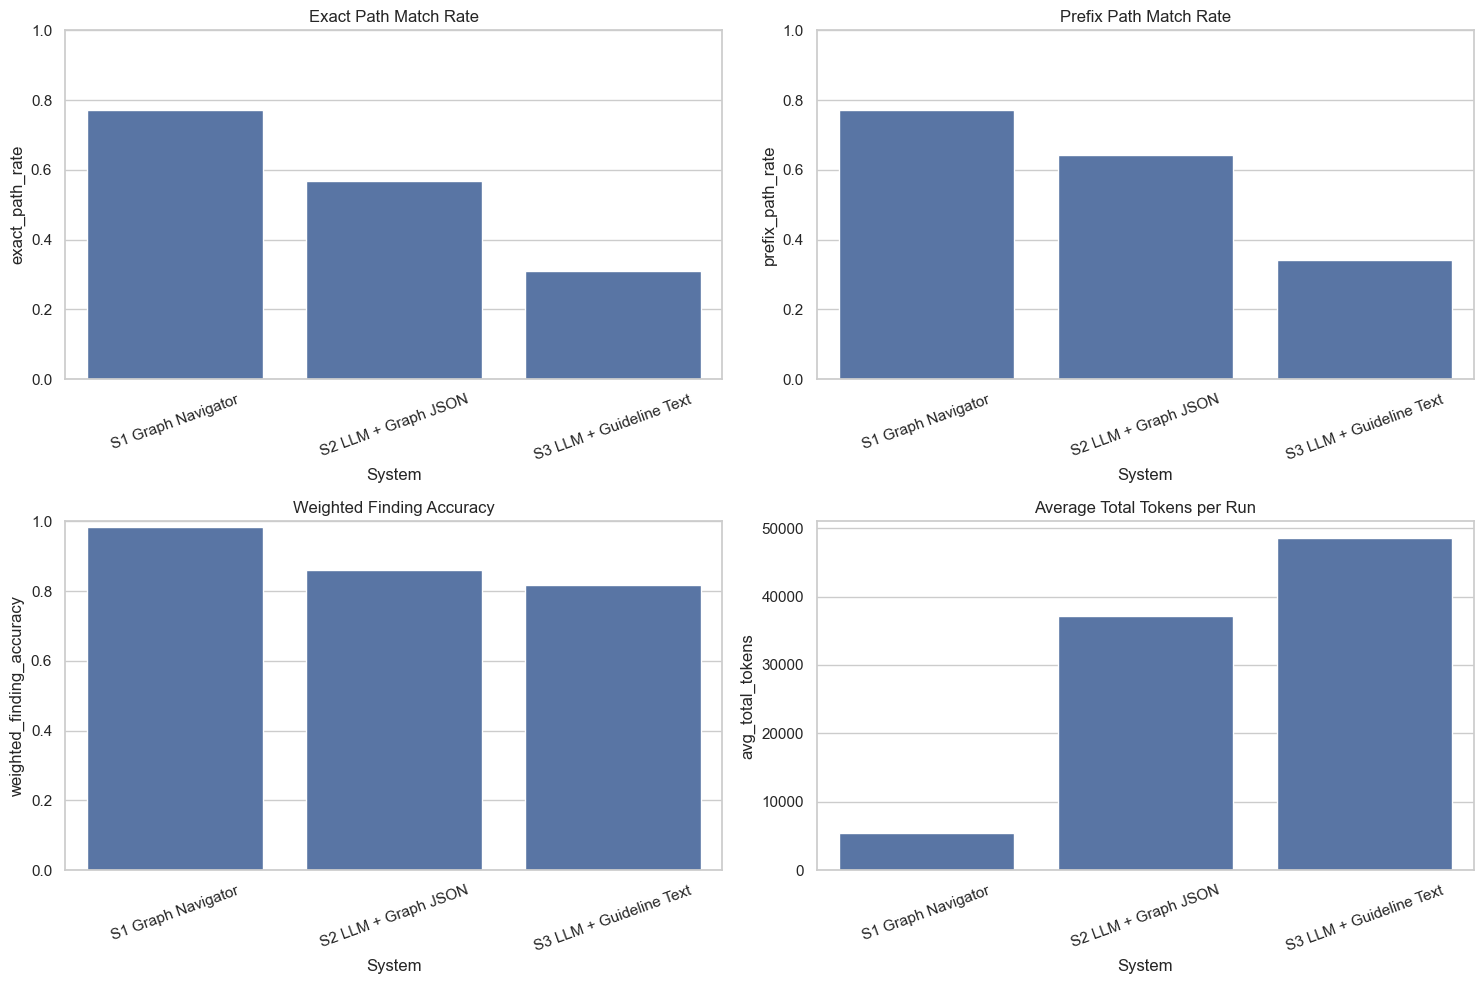

In [27]:
plot_df = system_summary.copy()
plot_df['System'] = plot_df['system_short'].astype(str)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.barplot(data=plot_df, x='System', y='exact_path_rate', ax=axes[0, 0], order=SYSTEM_SHORT_ORDER)
axes[0, 0].set_title('Exact Path Match Rate')
axes[0, 0].set_ylim(0, 1)
axes[0, 0].tick_params(axis='x', rotation=20)

sns.barplot(data=plot_df, x='System', y='prefix_path_rate', ax=axes[0, 1], order=SYSTEM_SHORT_ORDER)
axes[0, 1].set_title('Prefix Path Match Rate')
axes[0, 1].set_ylim(0, 1)
axes[0, 1].tick_params(axis='x', rotation=20)

sns.barplot(data=plot_df, x='System', y='weighted_finding_accuracy', ax=axes[1, 0], order=SYSTEM_SHORT_ORDER)
axes[1, 0].set_title('Weighted Finding Accuracy')
axes[1, 0].set_ylim(0, 1)
axes[1, 0].tick_params(axis='x', rotation=20)

sns.barplot(data=plot_df, x='System', y='avg_total_tokens', ax=axes[1, 1], order=SYSTEM_SHORT_ORDER)
axes[1, 1].set_title('Average Total Tokens per Run')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
fig.savefig(FIG_OUTPUT_DIR / 'system_metric_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

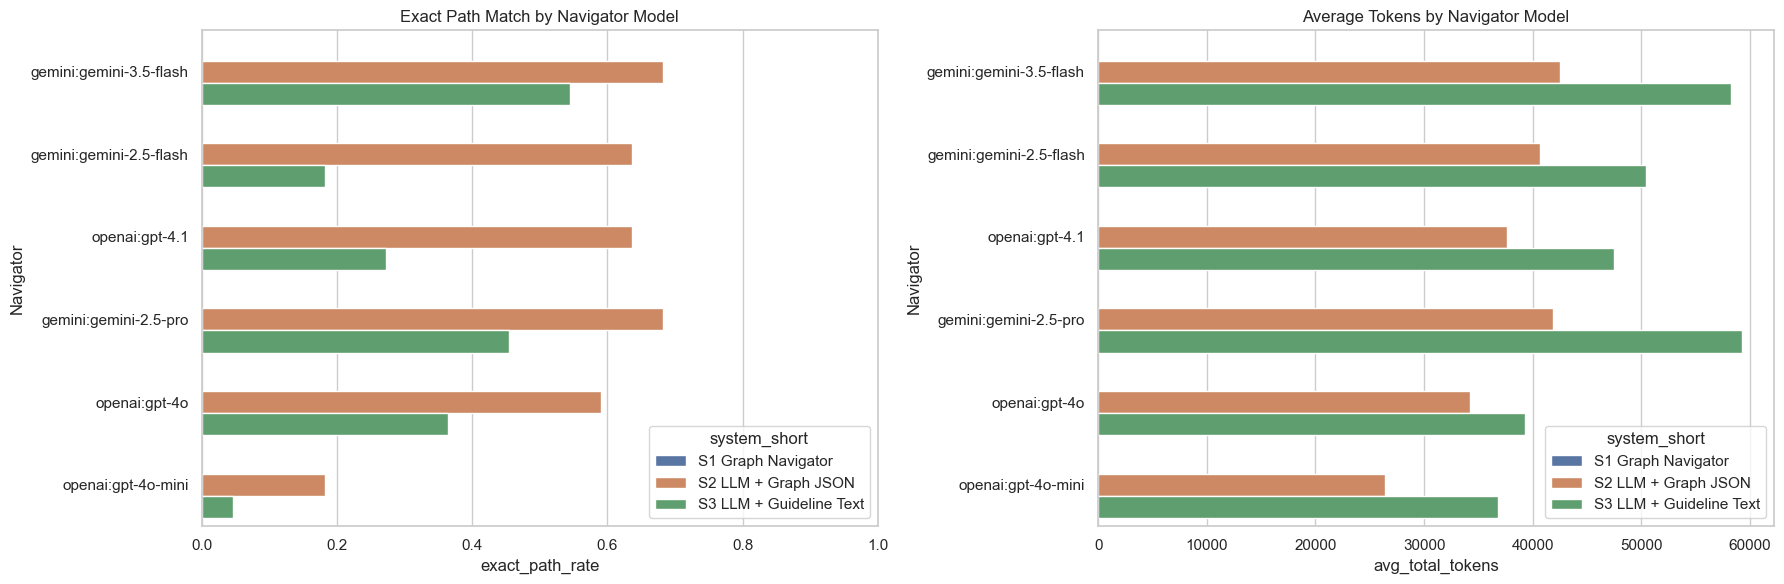

In [28]:
nav_plot = nav_model_summary[nav_model_summary['system_short'] != 'S1 Graph Navigator'].copy()
nav_plot['Navigator'] = nav_plot['nav_label']

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=nav_plot,
    y='Navigator',
    x='exact_path_rate',
    hue='system_short',
    ax=axes[0],
)
axes[0].set_title('Exact Path Match by Navigator Model')
axes[0].set_xlim(0, 1)

sns.barplot(
    data=nav_plot,
    y='Navigator',
    x='avg_total_tokens',
    hue='system_short',
    ax=axes[1],
)
axes[1].set_title('Average Tokens by Navigator Model')

plt.tight_layout()
fig.savefig(FIG_OUTPUT_DIR / 'navigator_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

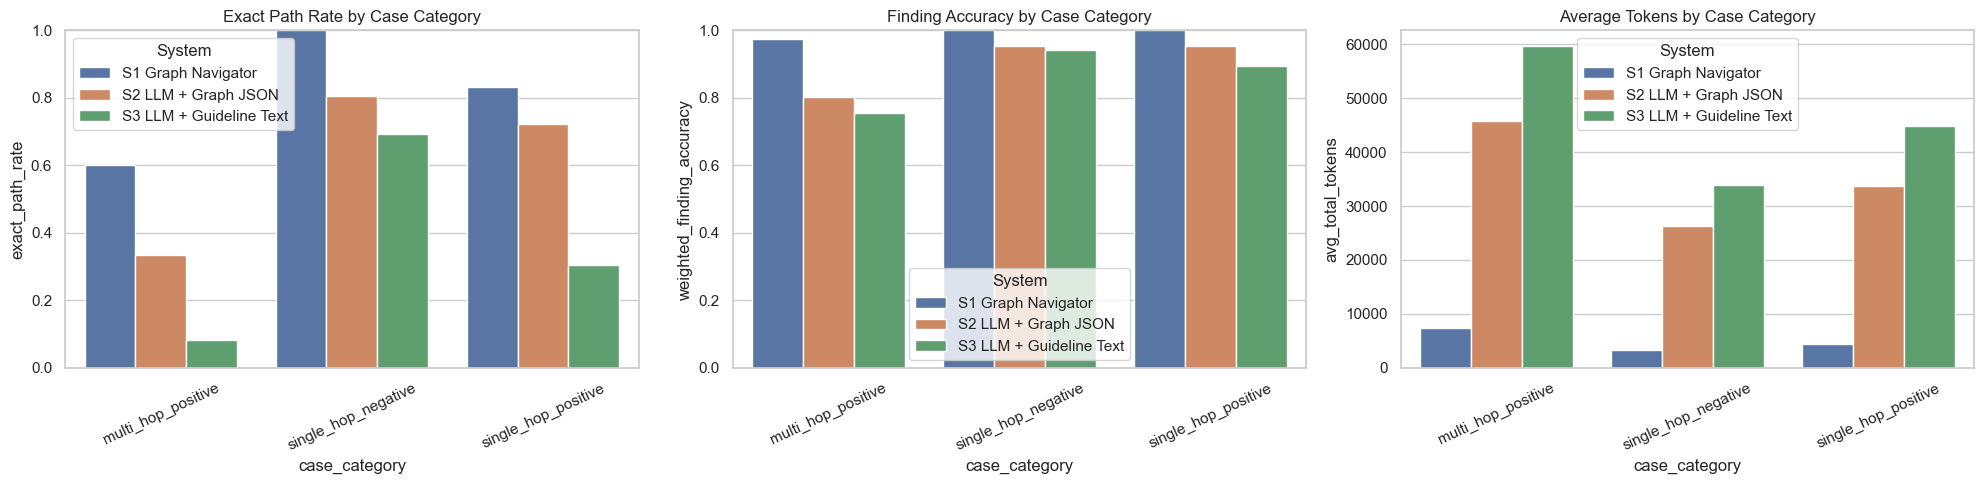

In [29]:
category_plot = category_summary.copy()
category_plot['System'] = category_plot['system_short'].astype(str)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.barplot(data=category_plot, x='case_category', y='exact_path_rate', hue='System', ax=axes[0])
axes[0].set_title('Exact Path Rate by Case Category')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=25)

sns.barplot(data=category_plot, x='case_category', y='weighted_finding_accuracy', hue='System', ax=axes[1])
axes[1].set_title('Finding Accuracy by Case Category')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=25)

sns.barplot(data=category_plot, x='case_category', y='avg_total_tokens', hue='System', ax=axes[2])
axes[2].set_title('Average Tokens by Case Category')
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
fig.savefig(FIG_OUTPUT_DIR / 'category_metric_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## Hypothesis-oriented interpretation table

The table below maps the research hypothesis to measurable indicators in the evaluation outputs.

In [30]:
hypothesis_table = pd.DataFrame([
    {
        'Hypothesis component': 'Clinical navigation is constrained by symbolic graph',
        'Expected measurable signal': 'High exact/prefix path match and low unsupported finding rate',
        'Best supporting metric': 'exact_path_rate, prefix_path_rate, unsupported_finding_rate',
        'Expected strongest system': 'System 1: Neurosymbolic Clinical Graph Navigator',
    },
    {
        'Hypothesis component': 'Separating navigation from conversation reduces hallucination',
        'Expected measurable signal': 'Fewer extra and mismatched findings',
        'Best supporting metric': 'extra_findings, mismatched_findings, unsupported_finding_rate',
        'Expected strongest system': 'System 1: Neurosymbolic Clinical Graph Navigator',
    },
    {
        'Hypothesis component': 'Structured graph JSON helps LLM navigation compared with raw text',
        'Expected measurable signal': 'System 2 outperforms System 3 in path fidelity and/or finding accuracy',
        'Best supporting metric': 'exact_path_rate, prefix_path_rate, weighted_finding_accuracy',
        'Expected strongest system': 'System 2 > System 3',
    },
    {
        'Hypothesis component': 'Raw guideline text increases reasoning burden',
        'Expected measurable signal': 'Higher token consumption for text-only clinical logic baseline',
        'Best supporting metric': 'avg_total_tokens, avg_nav_tokens',
        'Expected strongest system': 'System 3 uses more tokens than System 2 and System 1',
    },
])

hypothesis_table.to_csv(TABLE_OUTPUT_DIR / 'hypothesis_metric_mapping.csv', index=False)
hypothesis_table

,Hypothesis component,Expected measurable signal,Best supporting metric,Expected strongest system
0,Clinical navigation is constrained by symbolic...,High exact/prefix path match and low unsupport...,"exact_path_rate, prefix_path_rate, unsupported...",System 1: Neurosymbolic Clinical Graph Navigator
1,Separating navigation from conversation reduce...,Fewer extra and mismatched findings,"extra_findings, mismatched_findings, unsupport...",System 1: Neurosymbolic Clinical Graph Navigator
2,Structured graph JSON helps LLM navigation com...,System 2 outperforms System 3 in path fidelity...,"exact_path_rate, prefix_path_rate, weighted_fi...",System 2 > System 3
3,Raw guideline text increases reasoning burden,Higher token consumption for text-only clinica...,"avg_total_tokens, avg_nav_tokens",System 3 uses more tokens than System 2 and Sy...


## Compact results text for paper draft

Run this cell after the summaries above to generate a concise paragraph with the observed values from your CSV/JSON artifacts.

In [31]:
def pct(x):
    if pd.isna(x):
        return 'NA'
    return f'{100 * float(x):.1f}%'

for _, row in system_summary.iterrows():
    print(f"{row['system_short']}:")
    print(f"  runs: {int(row['runs'])}; unique cases: {int(row['unique_cases'])}")
    print(f"  exact path match: {pct(row['exact_path_rate'])}")
    print(f"  prefix path match: {pct(row['prefix_path_rate'])}")
    print(f"  weighted finding accuracy: {pct(row['weighted_finding_accuracy'])}")
    print(f"  unsupported finding rate: {pct(row['unsupported_finding_rate'])}")
    print(f"  average total tokens/run: {row['avg_total_tokens']:.1f}")
    print()

S1 Graph Navigator:
  runs: 22; unique cases: 22
  exact path match: 77.3%
  prefix path match: 77.3%
  weighted finding accuracy: 98.4%
  unsupported finding rate: 1.6%
  average total tokens/run: 5495.9

S2 LLM + Graph JSON:
  runs: 132; unique cases: 22
  exact path match: 56.8%
  prefix path match: 64.4%
  weighted finding accuracy: 86.1%
  unsupported finding rate: 1.6%
  average total tokens/run: 37211.9

S3 LLM + Guideline Text:
  runs: 132; unique cases: 22
  exact path match: 31.1%
  prefix path match: 34.1%
  weighted finding accuracy: 81.9%
  unsupported finding rate: 1.3%
  average total tokens/run: 48555.8



## Save normalized row-level data

The final cell saves the normalized row-level dataframe so the same cleaned data can be reused in tables or manuscript figures.

In [32]:
normalized_path = TABLE_OUTPUT_DIR / 'normalized_phase2_eval_rows.csv'
df.to_csv(normalized_path, index=False)
print('Saved normalized rows:', normalized_path)
print('Saved tables to:', TABLE_OUTPUT_DIR)
print('Saved figures to:', FIG_OUTPUT_DIR)

Saved normalized rows: /Users/rakib/Downloads/mental-health-research/detector_outputs/phase2_eval_runs/comparison_tables/normalized_phase2_eval_rows.csv
Saved tables to: /Users/rakib/Downloads/mental-health-research/detector_outputs/phase2_eval_runs/comparison_tables
Saved figures to: /Users/rakib/Downloads/mental-health-research/detector_outputs/phase2_eval_runs/comparison_figures
